In [2]:

import numpy as np
import matplotlib.pyplot as plt
import wendy

# --- Parameters ---
N = 100000
H = sigma = 1.0
dt = 0.05
nleap = 2

t_A = 0.0
t_B_values = (50.0,60.0)
tmax = 160.0

A1, L = 0.40, 1.2     # First kick
A2, a = 0.20, 1.0     # Plummer kick

# --- Same equilibrium for every simulation ---
rng = np.random.default_rng(42)

z0 = 2 * H * np.arctanh(2 * rng.random(N) - 1)
v0 = rng.normal(0, sigma, N)

z0 -= z0.mean()
v0 -= v0.mean()
m = np.ones(N) / N

# --- Impulses ---
def kick_A(z):
    return -A1 * np.cos(z / L)

def kick_B(z):
    return -A2 * 2 * a * z / (z**2 + a**2)

# --- Recording parameters ---
nt = round(tmax / dt)

times = np.arange(nt + 1) * dt

edges = np.linspace(-6, 6, 81)
dz = edges[1] - edges[0]

# Follow the same AB distribution from A through winding, B, and the echo.
# Snapshots are recorded after any impulse at that output time.
snapshot_steps = {round(t_A / dt), round((t_A + 10.0) / dt)}
for delay in t_B_values:
    step_B = round(delay / dt)
    snapshot_steps.update({step_B - 1, step_B,
                           round((2 * delay - t_A) / dt)})
snapshot_times = [step * dt for step in sorted(snapshot_steps)]

def simulate(use_A=False, use_B=False,t_B=None):
    
    k_B= round(t_B/dt) if use_B else None
    z, v = z0.copy(), v0.copy()

    if use_A:
        dv = kick_A(z)
        v += dv - dv.mean()

    g = wendy.nbody(z, v, m, dt, approx=True, nleap=nleap)

    density = np.zeros((nt + 1, len(edges) - 1))
    signal = np.zeros(nt + 1)
    snapshots = {}

    for i in range(nt + 1):

        # Apply second impulse exactly at t_B
        if use_B and i == k_B:
            dv = kick_B(z)
            v = v + dv - dv.mean()
            g = wendy.nbody(z, v, m, dt,
                            approx=True, nleap=nleap)

        # Work relative to the instantaneous centre of mass
        zc = z - z.mean()
        if i in snapshot_steps:
            snapshots[i] = (zc.copy(), (v - v.mean()).copy())
        density[i] = np.histogram(zc, bins=edges)[0] / (N * dz)

        # Bounded odd-density observable
        signal[i] = np.mean(np.sin(zc / H))

        if i < nt:
            z, v = next(g)

    return density, signal, snapshots

# Shared controls
print("Running: unperturbed")
result_0 = simulate(False, False)

print("Running: A only")
result_A = simulate(True, False)

# Separate B and AB runs for each delay
results_by_delay = {}

for t_B in t_B_values:
    print(f"Running: B only, t_B={t_B:g}")
    result_B = simulate(False, True, t_B=t_B)

    print(f"Running: both kicks, t_B={t_B:g}")
    result_AB = simulate(True, True, t_B=t_B)

    results_by_delay[t_B] = {
        "0": result_0,
        "A": result_A,
        "B": result_B,
        "AB": result_AB,
    }


Running: unperturbed
Running: A only
Running: B only, t_B=50
Running: both kicks, t_B=50
Running: B only, t_B=60
Running: both kicks, t_B=60


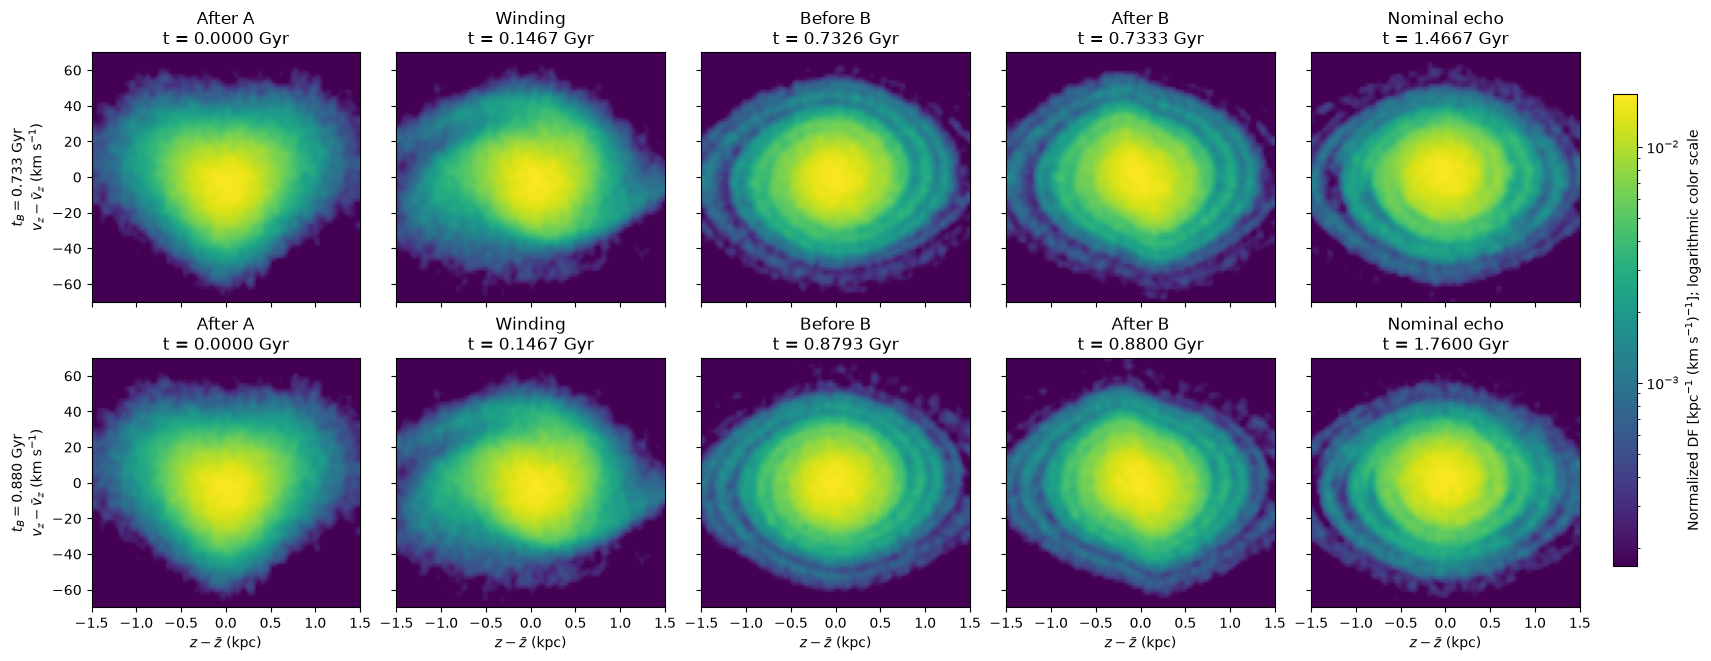

In [8]:
# Follow the SAME both-kick DF through time; no DF subtraction.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter

# H = 300 pc and sigma = 20 km/s; simulation H = sigma = 1.
H_phys_kpc = 0.300
sigma_phys_kms = 20.0
time_unit_Gyr = 0.97779222168 * H_phys_kpc / sigma_phys_kms

stage_names = ("After A", "Winding", "Before B", "After B", "Nominal echo")
stage_steps = {}
for delay in t_B_values:
    step_B = round(delay / dt)
    stage_steps[delay] = (round(t_A / dt), round((t_A + 10.0) / dt),
                          step_B - 1, step_B, round((2 * delay - t_A) / dt))

# Previously saved late-time snapshots cannot reconstruct the earlier DF.
missing = [(delay, step * dt) for delay in t_B_values
           for step in stage_steps[delay]
           if step not in results_by_delay[delay]["AB"][2]]
if missing:
    raise RuntimeError(
        "The earlier snapshots have not been recorded. Run the FIRST simulation "
        "cell once, then rerun this plotting cell. Missing (t_B, time) in code "
        f"units: {missing}"
    )

# Physical coordinates, identical bins, and one-bin smoothing in every panel.
# This smoothing changes the display only, not the simulated distribution.
phase_z_edges = np.linspace(-5 * H_phys_kpc, 5 * H_phys_kpc, 101)
phase_v_edges = np.linspace(-3.5 * sigma_phys_kms, 3.5 * sigma_phys_kms, 81)
phase_bin_area = np.diff(phase_z_edges)[0] * np.diff(phase_v_edges)[0]
phase_panels = []

for delay in t_B_values:
    row = []
    for step in stage_steps[delay]:
        # Positions and velocities are already relative to this run's COM.
        z_centered, v_centered = results_by_delay[delay]["AB"][2][step]
        counts, _, _ = np.histogram2d(
            z_centered * H_phys_kpc, v_centered * sigma_phys_kms,
            bins=(phase_z_edges, phase_v_edges)
        )
        probability_density = counts / (len(z_centered) * phase_bin_area)
        row.append(gaussian_filter(probability_density, sigma=1.0))
    phase_panels.append(row)

# A shared logarithmic scale makes low-density winding easier to see.
phase_max = max(panel.max() for row in phase_panels for panel in row)
if not np.isfinite(phase_max) or phase_max <= 0:
    raise ValueError("No finite, positive phase-space density in the plotting window.")
phase_norm = LogNorm(vmin=phase_max / 100.0, vmax=phase_max, clip=True)
phase_cmap = plt.get_cmap("viridis").copy()
phase_cmap.set_bad(phase_cmap(0.0))

fig_phase, axes_phase = plt.subplots(
    len(t_B_values), len(stage_names), figsize=(17, 6.5),
    sharex=True, sharey=True, squeeze=False, layout="constrained"
)
phase_extent = [phase_z_edges[0], phase_z_edges[-1],
                phase_v_edges[0], phase_v_edges[-1]]

for row_index, delay in enumerate(t_B_values):
    for column, (stage, step, panel) in enumerate(zip(
            stage_names, stage_steps[delay], phase_panels[row_index])):
        ax_phase = axes_phase[row_index, column]
        image_phase = ax_phase.imshow(
            panel.T, origin="lower", extent=phase_extent, aspect="auto",
            cmap=phase_cmap, norm=phase_norm
        )
        ax_phase.set_title(f"{stage}\nt = {step * dt * time_unit_Gyr:.4f} Gyr")
        if row_index == len(t_B_values) - 1:
            ax_phase.set_xlabel(r"$z-\bar z$ (kpc)")
    axes_phase[row_index, 0].set_ylabel(
        rf"$t_B={delay * time_unit_Gyr:.3f}$ Gyr" + "\n" +
        r"$v_z-\bar v_z$ (km s$^{-1}$)"
    )


fig_phase.colorbar(
    image_phase, ax=axes_phase.ravel().tolist(), shrink=0.85, pad=0.015,
    label=r"Normalized DF [kpc$^{-1}$ (km s$^{-1}$)$^{-1}$]; logarithmic color scale"
)
fig_phase.savefig("phase_mixing.pdf", bbox_inches="tight")
plt.show()


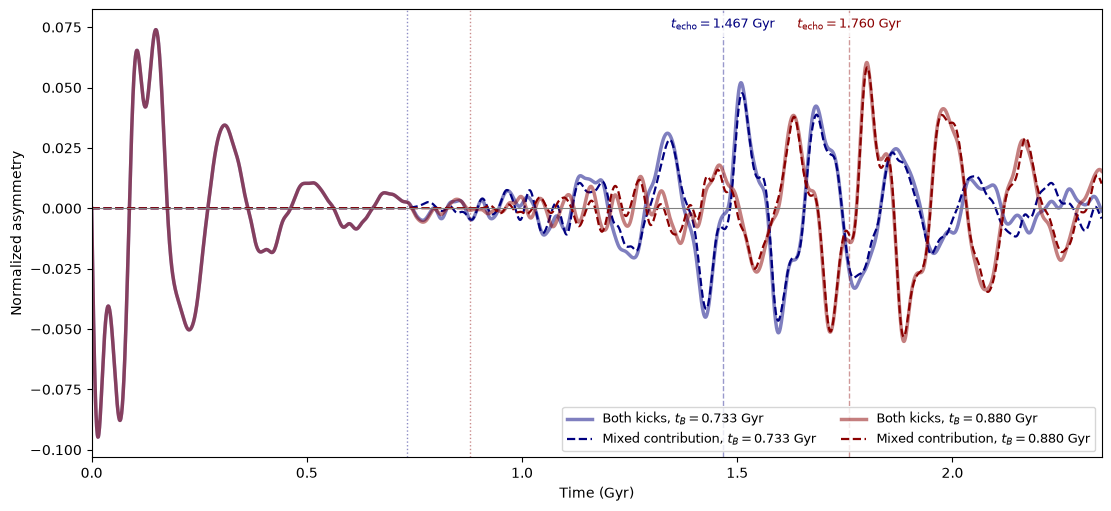

In [9]:
# Compare both second-kick times using the saved simulations.
import numpy as np
import matplotlib.pyplot as plt

# Physical scaling discussed above: H = 300 pc, sigma = 20 km/s.
H_phys_kpc = 0.300
sigma_phys_kms = 20.0
time_unit_Gyr = 0.97779222168 * H_phys_kpc / sigma_phys_kms

fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")

for delay_index, t_B_case in enumerate(t_B_values):
    branches = results_by_delay[t_B_case]
    signals = {name: np.asarray(branches[name][1])
               for name in ("0", "A", "B", "AB")}
    S0 = signals["0"]
    if S0.ndim != 1 or len(S0) < 2:
        raise ValueError("The saved signal must be a one-dimensional time series.")
    for name, signal in signals.items():
        if signal.shape != S0.shape or not np.all(np.isfinite(signal)):
            raise ValueError(f"Invalid signal or unequal array lengths: {name}, t_B={t_B_case:g}")

    SA = signals["A"] - S0
    SB = signals["B"] - S0
    SAB = signals["AB"] - S0
    Smix = SAB - SA - SB

    # Build the time axis from the saved simulation length.
    t_code = np.arange(len(S0)) * dt
    t_echo_code = 2 * t_B_case - t_A
    if t_code[-1] < t_echo_code + 20.0 - 1e-9:
        raise ValueError("Record at least 20 time units beyond each nominal echo.")
    t_gyr = t_code * time_unit_Gyr
    t_B_gyr = t_B_case * time_unit_Gyr
    t_echo_gyr = t_echo_code * time_unit_Gyr
    color = ("navy", "darkred")[delay_index % 2]

    ax.plot(t_gyr, SAB, color=color, lw=2.5, alpha=0.5,
            label=rf"Both kicks, $t_B={t_B_gyr:.3f}$ Gyr")
    ax.plot(t_gyr, Smix, color=color, ls="--", lw=1.6,
            label=rf"Mixed contribution, $t_B={t_B_gyr:.3f}$ Gyr")
    ax.axvline(t_B_gyr, color=color, ls=":", lw=1, alpha=0.45)
    ax.axvline(t_echo_gyr, color=color, ls="--", lw=1, alpha=0.4)
    ax.text(t_echo_gyr, 0.98,
            rf"$t_{{\rm echo}}={t_echo_gyr:.3f}$ Gyr",
            transform=ax.get_xaxis_transform(), ha="center", va="top",
            color=color, fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))

ax.axhline(0, color="gray", lw=0.8)
ax.set_xlim(0, max((len(results_by_delay[value]["0"][1]) - 1) * dt
                   for value in t_B_values) * time_unit_Gyr)
ax.set_xlabel("Time (Gyr)")
ax.set_ylabel("Normalized asymmetry")
ax.legend(ncol=2, loc="lower right", fontsize=9)
fig.savefig("echo_comparison.pdf", bbox_inches="tight")
plt.show()


In [5]:
# Times for both saved experiments, using the scaling in the plot above.
for t_B_case in t_B_values:
    duration = (len(results_by_delay[t_B_case]["0"][1]) - 1) * dt
    print(f"t_B = {t_B_case * time_unit_Gyr:.3f} Gyr; "
          f"nominal echo = {(2 * t_B_case - t_A) * time_unit_Gyr:.3f} Gyr; "
          f"saved duration = {duration * time_unit_Gyr:.3f} Gyr")


t_B = 0.733 Gyr; nominal echo = 1.467 Gyr; saved duration = 2.347 Gyr
t_B = 0.880 Gyr; nominal echo = 1.760 Gyr; saved duration = 2.347 Gyr
